# Clinical + Mutation — common-cohort comparison

This notebook reports the clinical + mutation model in the common cohort (N=110; 43 oligo, 67 poly), evaluated on the same frozen outer folds as the other six input configurations. Model families are selected by mean inner-CV macro-F1, not outer-test performance. Reporting cells load saved results only; no model is trained here.

The seven-way comparison is presented in the [summary of model results](20260913-summary-of-model-results-oligopoly.ipynb).

In [1]:
# Display precision only; analytical values and saved artifacts stay unchanged.
from pathlib import Path as _DisplayPath
import sys as _display_sys
_display_root = _DisplayPath.cwd()
while not (_display_root / "scripts").is_dir() and _display_root != _display_root.parent:
    _display_root = _display_root.parent
if str(_display_root) not in _display_sys.path:
    _display_sys.path.insert(0, str(_display_root))
from scripts.OligoPolyThesis.utils_ml_oligopoly import thesis_display

from pathlib import Path as P110Path
import sys as p110_sys
import pandas as p110_pd
from IPython.display import display, Image as P110Image, Markdown as P110Markdown
import matplotlib.pyplot as plt
p110_repo = next(p for p in [P110Path.cwd(), *P110Path.cwd().parents] if (p / 'scripts/OligoPolyThesis').is_dir())
if str(p110_repo) not in p110_sys.path:
    p110_sys.path.insert(0, str(p110_repo))
from scripts.OligoPolyThesis.utils_ml_oligopoly import load_primary110, plot_thesis_saved_figure
p110_root = P110Path('/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Common-Cohort-Modality-Comparison')
p110_bundle = load_primary110(p110_root)

p110_config = 'clinical_mutation'
p110_output = p110_root / 'primary_110' / p110_config
# Row 1 of the saved context table is the common-cohort result.
p110_context = p110_pd.read_csv(p110_output / f'{p110_config}_primary_110_context_comparison.csv').iloc[[1]].reset_index(drop=True)
p110_context['analysis_context'] = 'Common cohort (N=110)'
p110_primary_label = 'Common cohort (N=110)'
p110_primary_family = p110_context.iloc[0].selected_family



### Selected-model performance — Common cohort (N=110)

The selected family has the highest mean inner-CV macro-F1. Pooled metrics use concatenated held-out predictions and are not fold means.

In [3]:
thesis_display(p110_context.rename(columns={'analysis_context': 'Context', 'selected_family': 'Selected family', 'mean_inner_macro_f1': 'Mean inner-CV macro-F1', 'roc_auc': 'Pooled ROC-AUC', 'average_precision': 'Average Precision', 'balanced_accuracy': 'Balanced Accuracy', 'macro_f1': 'Macro-F1', 'precision': 'Precision', 'sensitivity': 'Sensitivity', 'specificity': 'Specificity', 'brier_score': 'Brier score'})[['Context', 'N', 'Selected family', 'Mean inner-CV macro-F1', 'Pooled ROC-AUC', 'Average Precision', 'Balanced Accuracy', 'Macro-F1', 'Precision', 'Sensitivity', 'Specificity', 'Brier score']])


,Context,N,Selected family,Mean inner-CV macro-F1,Pooled ROC-AUC,Average Precision,Balanced Accuracy,Macro-F1,Precision,Sensitivity,Specificity,Brier score
0,Common cohort (N=110),110,random_forest,0.589,0.670,0.792,0.621,0.623,0.700,0.731,0.512,0.220


### Train–test diagnostics — Common cohort (N=110)

The first table reports the selected family. Train and outer-test AUC are means across five outer folds; the gap is their difference. The all-family table is a secondary diagnostic, not a selection criterion.

In [4]:
p110_diagnostics = p110_pd.read_csv(p110_output / f'{p110_config}_primary_110_train_test.csv')
p110_primary_diag = p110_diagnostics.set_index('family').loc[p110_primary_family]
thesis_display(p110_pd.DataFrame([
    {'Context':p110_primary_label, 'Selected family':p110_primary_family, 'Mean train AUC':p110_primary_diag.roc_auc_train_mean,
     'Mean outer-test AUC':p110_primary_diag.roc_auc_test_mean,'Train–test AUC gap':p110_primary_diag.roc_auc_gap_mean},
]))
thesis_display(P110Markdown('**All common-cohort candidate families — diagnostic**'))
thesis_display(p110_diagnostics[['family','roc_auc_train_mean','roc_auc_train_std','roc_auc_test_mean','roc_auc_test_std','roc_auc_gap_mean','roc_auc_gap_std']].assign(Context=p110_primary_label))


,Context,Selected family,Mean train AUC,Mean outer-test AUC,Train–test AUC gap
0,Common cohort (N=110),random_forest,0.989,0.664,0.324


**All common-cohort candidate families — diagnostic**

,family,roc_auc_train_mean,roc_auc_train_std,roc_auc_test_mean,roc_auc_test_std,roc_auc_gap_mean,roc_auc_gap_std,Context
0,logreg_l1,0.968,0.059,0.669,0.063,0.298,0.055,Common cohort (N=110)
1,random_forest,0.989,0.016,0.664,0.060,0.324,0.058,Common cohort (N=110)
2,xgboost,0.704,0.076,0.454,0.167,0.251,0.224,Common cohort (N=110)


### ROC curve — Common cohort (N=110)

Selected-family pooled OOF predictions from the shared 110-patient comparison.

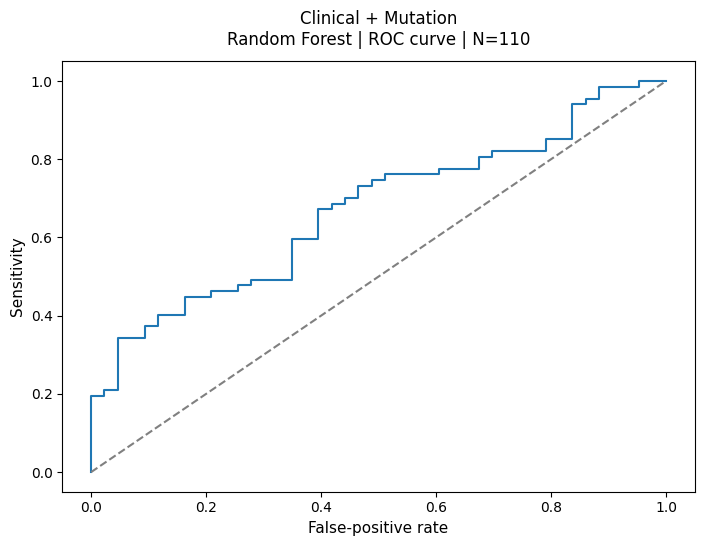

In [15]:
fig = plot_thesis_saved_figure('roc', 'clinical_mutation')
plt.show()


### Precision–Recall curve — Common cohort (N=110)

Selected-family pooled OOF predictions from the shared 110-patient comparison.

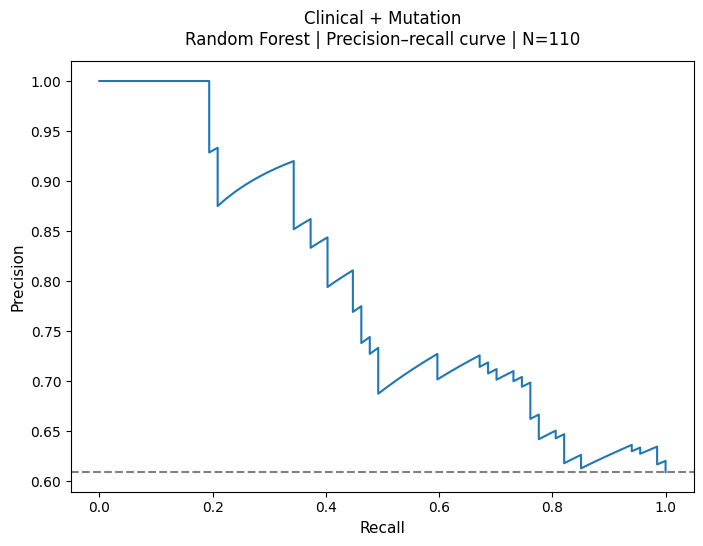

In [16]:
fig = plot_thesis_saved_figure('pr', 'clinical_mutation')
plt.show()


### Confusion matrix — Common cohort (N=110)

Selected-family pooled OOF predictions from the shared 110-patient comparison.

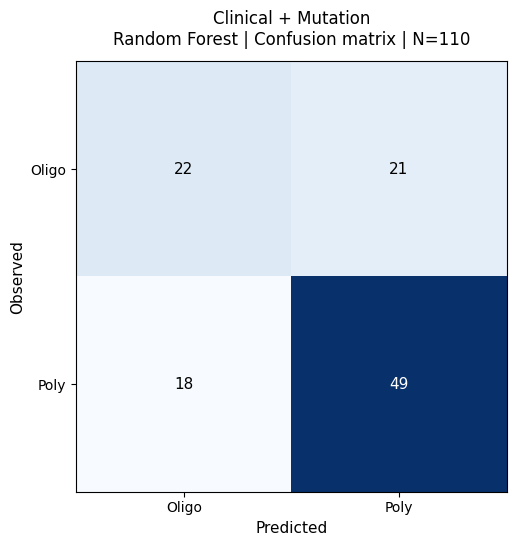

In [17]:
fig = plot_thesis_saved_figure('confusion_matrix', 'clinical_mutation')
plt.show()


### Family selection — Common cohort (N=110)

The selected family is determined by the highest mean inner-CV macro-F1. Values summarise five outer folds. The common-cohort protocol uses compact grids, training-local preprocessing within inner and outer folds, seeded MI, no resampling and fit-local XGBoost weighting.

In [5]:
p110_selection_comparison = p110_bundle['ranking'].query('configuration == @p110_config')[['family','mean_inner_macro_f1','std_inner_macro_f1']].copy()
p110_selection_comparison['Selected — '+p110_primary_label] = p110_selection_comparison.family.eq(p110_primary_family)
p110_selection_comparison = p110_selection_comparison.rename(columns={
    'mean_inner_macro_f1':p110_primary_label+' mean inner macro-F1',
    'std_inner_macro_f1':p110_primary_label+' SD'}).sort_values('family').reset_index(drop=True)
thesis_display(p110_selection_comparison)

,family,Common cohort (N=110) mean inner macro-F1,Common cohort (N=110) SD,Selected — Common cohort (N=110)
0,logreg_l1,0.563,0.038,False
1,random_forest,0.589,0.025,True
2,xgboost,0.535,0.041,False


### Calibration curve — Common cohort (N=110)

Selected-family pooled OOF predictions from the shared 110-patient comparison.

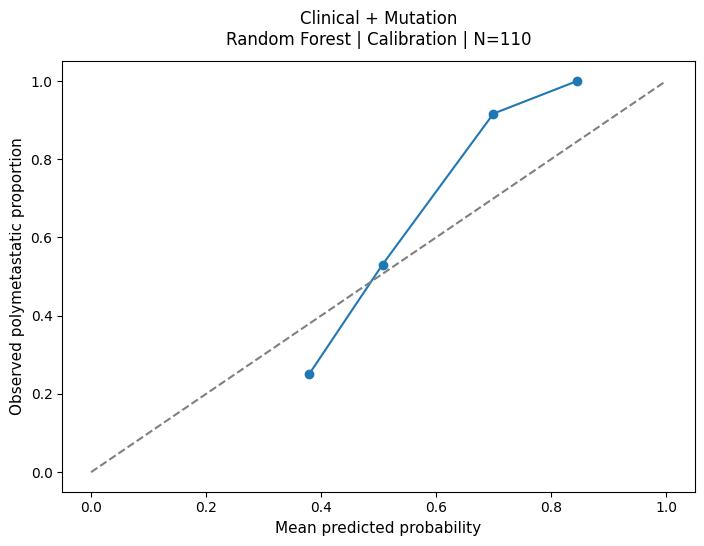

In [18]:
fig = plot_thesis_saved_figure('calibration', 'clinical_mutation')
plt.show()
